In [1]:
import os
import torch
from models.vit_sae import ViTSAE

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_vivit_sae_model(model_file, num_classes=43):
    """
    Load a pre-trained ViViT model from the given file path.
    Args:
        args (Namespace): Arguments containing the model's state dictionary path.
    Returns:
        dict: Loaded state dictionary.
    """
    state_dict = torch.load(model_file,map_location=device)
    model = ViTSAE(num_classes=num_classes, output_attentions=True).to(device)
    model.load_state_dict(state_dict)
    return model

c:\Users\phil2\Documents\GitHub\ImageVAE\.env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device

device(type='cpu')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F


def vit_sae_forward(model, image_tensor, threshold=0.2):
    """
    Perform a forward pass through the ViViT-SAE model in inference mode.
    Args:
        video_tensor (torch.Tensor): Preprocessed video input tensor.
    Returns:
        tuple: (sae_latent, att_features) as CPU tensors.
    """
    model.eval()
    with torch.no_grad():
        image_tensor = image_tensor.to(device)
        att_weights = model.vit(image_tensor).attentions[-2][:,:,0,1:].mean(dim=1).squeeze(0)
        att_features = model.vit(image_tensor).last_hidden_state[:, 1:] 
        sparse_logits, _, _, logits, _, _ = model(image_tensor)  # (196, D) 
        sparse_features = (sparse_features > threshold).float()
    return att_features, att_weights, sparse_logits, logits


def get_patch_scores(model, patch_features, att_maps, neuron_idx):
    """
    Compute per-patch contribution scores for a given SAE neuron on a single image.
    Returns a heatmap (14x14) and the original image.
    """
    model.eval()
    with torch.no_grad():
        neuron_weight = model.encoder.weight[neuron_idx]  # (D,)
        patch_scores = torch.einsum("id,d->i", patch_features.squeeze(0), neuron_weight).squeeze(0)  # (196,)
        weighted_patches = patch_scores * att_maps
        return weighted_patches.view(14, 14).cpu()


def apply_scalar_to_patches(image, patch_size=16, scalars=1.0):
    image = image[0]
    H, W, C = image.shape
    new_image = np.zeros_like(image)
    
    h_patches = H // patch_size
    w_patches = W // patch_size
    
    # Handle either a single scalar or one per patch
    for i in range(h_patches):
        for j in range(w_patches):
            patch = image[i*patch_size:(i+1)*patch_size,
                          j*patch_size:(j+1)*patch_size, :]
            scaled_patch = patch * scalars
            new_image[i*patch_size:(i+1)*patch_size,
                      j*patch_size:(j+1)*patch_size, :] = scaled_patch
    
    return new_image


def visualize_img_heatmap(image, patches_heatmap, title=None):
    """
    Overlay a heatmap on the image showing patch contributions, and show actual video frame if provided.
    """
    patches_heatmap = patches_heatmap.unsqueeze(0).unsqueeze(0)
    upsampled = F.interpolate(patches_heatmap, size=(image.shape[1], image.shape[2]), mode='bilinear').squeeze().numpy()
    image_np = image.permute(1, 2, 0).numpy()
    image_np = np.clip(image_np, 0, 1)

    plt.figure(figsize=(4, 4))
    plt.imshow(image_np)
    plt.imshow(upsampled, cmap='jet', alpha=0.5)
    plt.axis('off')
    if title:
        plt.title(title)
    plt.show()

In [4]:
dataset_dir = os.path.join("..", "GTSRB") # Place any dataset here
txt_file = os.path.join("..", "record-vitsae", dataset_dir.split(os.sep)[1], "top_k_neurons.txt")
#model_path = os.path.join("..", "model-vitsae",dataset_dir.split(os.sep)[1], "best_model_ce_kl_gtsrb.pth")
model_path = os.path.join("..", "model-vitsae",dataset_dir.split(os.sep)[1], "best_model_ce_cs-1.pth")

model = load_vivit_sae_model(model_path, num_classes=43)

Some weights of ViTModel were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.3271, 0.3350, 0.3469, 0.3144, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.3042, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.3206, 0.3599, 0.0000,
        0.0000, 0.0000, 0.0000, 0.3482, 0.3826, 0.3062, 0.3335, 0.4178, 0.4136,
        0.4439, 0.4260, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.3502, 0.4108, 0.0000, 0.0000,
        0.3164, 0.4506, 0.4406, 0.0000, 0.3269, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.3540, 0.3160,
        0.0000, 0.0000, 0.0000, 0.3325, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 

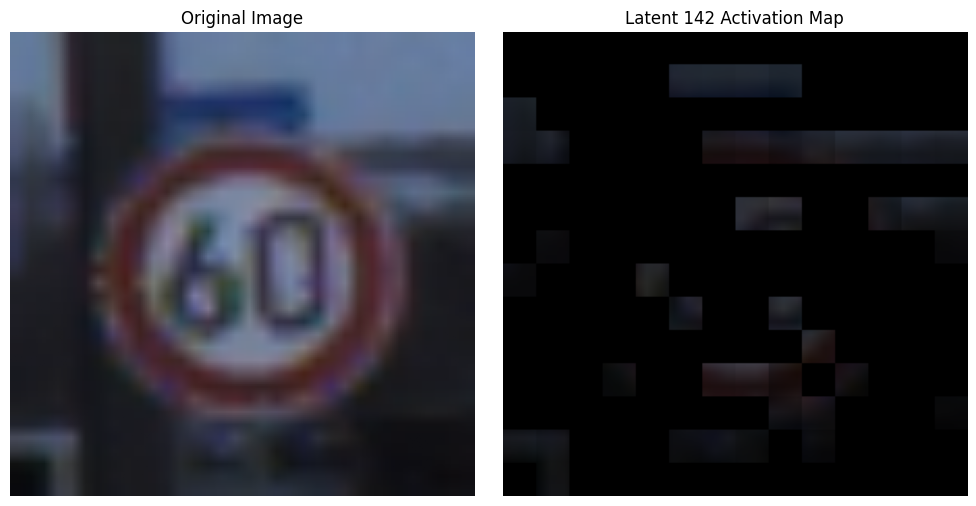

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.3353, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.3006, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.3150,
        0.3128, 0.0000, 0.0000, 0.3029, 0.0000, 0.3047, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.3086, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 

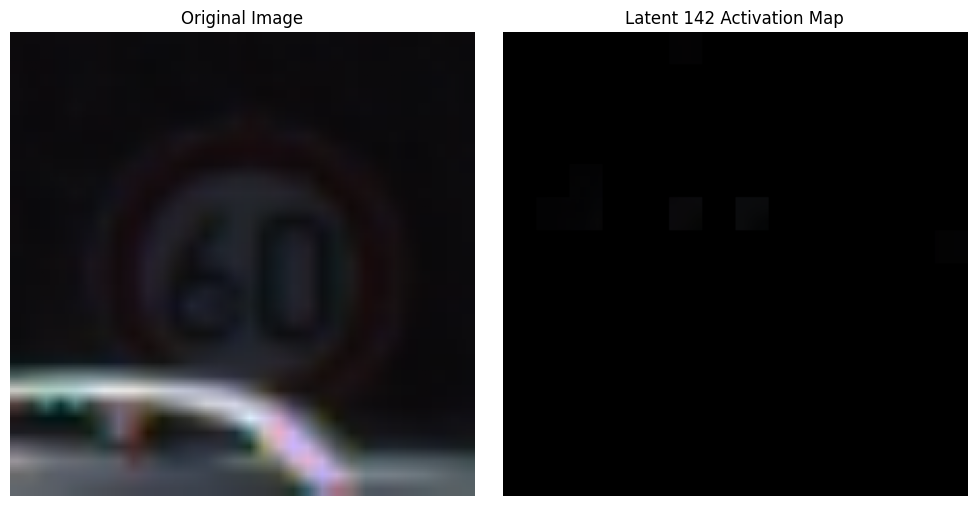

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.3043, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 

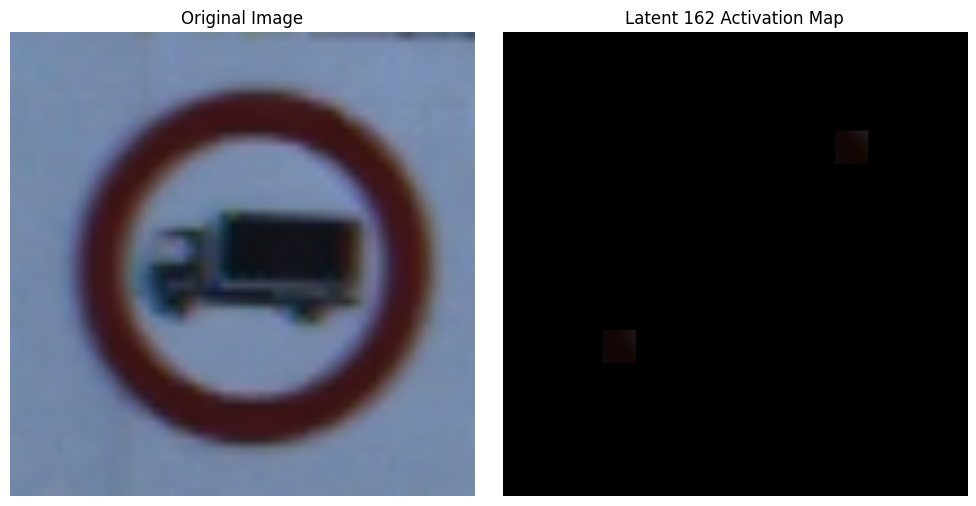

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.3179, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 

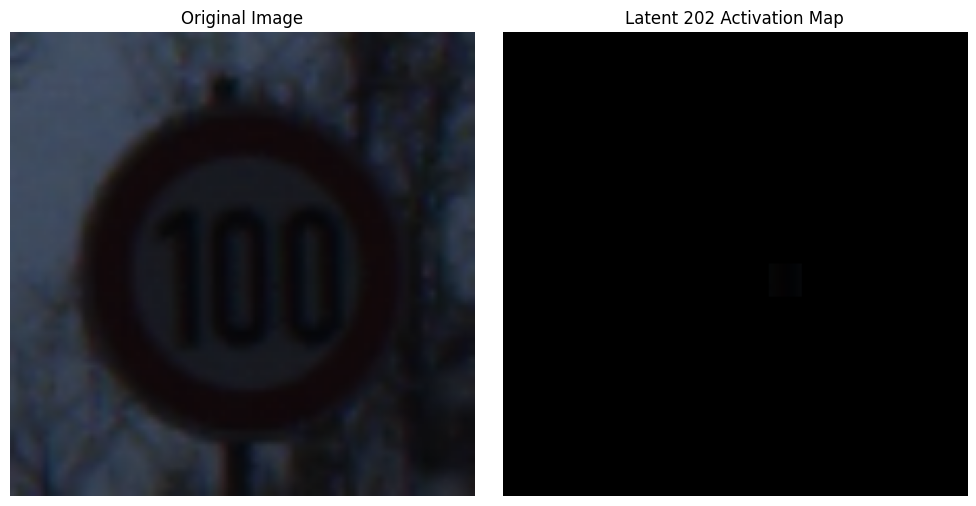

KeyboardInterrupt: 

In [6]:
from torchvision import transforms
from imageio.v2 import imread
from PIL import Image

# This is to only get 6 frames per video
samples = 5 # Make float("inf") if you don't want to sample and get every frame
patch_size = 16
img_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])
with open(txt_file, 'r') as file:
    for i, line in enumerate(file):
        # Get neuron and file path
        neuron_idx, img_file = line.strip().split(':')
        img_file = os.path.join("..", img_file.strip())
        #img_file = os.path.join("../data/flowers-102/jpg", f"{img_file.strip()[:-4]}.jpg")
        image = imread(img_file)
        pillow_image = Image.fromarray(image)
        image_tensor = img_transform(pillow_image).unsqueeze(0)
        sparse_features, att_maps, sparse_logits, logits = vit_sae_forward(model, image_tensor)
        neuron_activations = sparse_logits.cpu()[0, :, int(neuron_idx)]
        neuron_activations = torch.where(neuron_activations < 0.3, torch.tensor(0.0, device=neuron_activations.device), neuron_activations)
        count = (neuron_activations >= 0.0).sum().numpy()
        if torch.all(neuron_activations == 0) or count < (196 * 0.1):
            #print(f"All values in neuron_activations are zero for neuron index {neuron_idx}. Skipping...")
            continue
        print(neuron_activations, neuron_idx)
        if int(neuron_idx) == 156:
            print(sparse_logits.cpu())
            break
        #break

        # Get patches for image: shape -> (1, 3*16*16, 196)
        patches = F.unfold(image_tensor, kernel_size=patch_size, stride=patch_size)

        # Reshape to (196, 3, 16, 16)
        patches = patches.squeeze(0).transpose(0, 1).reshape(196, 3, patch_size, patch_size)
        
        # shape: (196, 3, 16, 16) * (196, 1, 1, 1)
        highlighted_patches = patches * neuron_activations[:, None, None, None]

        # reshape back to unfold shape: (1, 3*16*16, 196)
        highlighted_patches = highlighted_patches.reshape(196, -1).transpose(0, 1).unsqueeze(0)

        # fold to (1, 3, 224, 224)
        highlighted_image = F.fold(highlighted_patches, output_size=(224, 224), kernel_size=patch_size, stride=patch_size)
        

        # Permute image to (1, 224, 224, 3) and view image
        img_np = highlighted_image.squeeze().permute(1, 2, 0).detach().numpy()
        img_np = img_np.clip(0, 1)

        orig_img_np = image_tensor.squeeze().permute(1, 2, 0).detach().numpy()
        orig_img_np = orig_img_np.clip(0, 1)

        # Display original and highlighted images side by side
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(orig_img_np)
        axes[0].axis('off')
        axes[0].set_title("Original Image")

        axes[1].imshow(img_np)
        axes[1].axis('off')
        axes[1].set_title(f"Latent {int(neuron_idx)} Activation Map")

        plt.tight_layout()
        plt.show()

        #if i > samples:
        #    break

In [ ]:
import os
import numpy as np
import csv

# Directory containing the .npy files
npy_dir = os.path.join("..", "activations", "GTSRB")

# List all .npy files in the directory
npy_files = [f for f in os.listdir(npy_dir) if f.endswith('.npy')]

# Load and print the contents of each .npy file
# Prepare CSV file to save the data
csv_file_path = os.path.join("..", "activations", "gtsrb_ce_info_activations_summary.csv")
with open(csv_file_path, mode='w', newline='') as csv_file:
    csv_writer = csv.writer(csv_file)
        
    # Write the header row
    header = ["File Name"] + [f"act_{i}" for i in range(768*16)] + ["label"]
    csv_writer.writerow(header)
    for npy_file in npy_files:
        file_path = os.path.join(npy_dir, npy_file)
        label = int(file_path.split('_')[-1][:-4])
        data = np.load(file_path)
        
        # Write data for the current file
        #csv_writer.writerow([npy_file] + data.tolist())
        # Select the top 5 neurons with the highest activation values and set them to 1
        #top_5_indices = np.argsort(data)[-5:]
        #low5_indices = np.argsort(data)[:5]
        #data[top_5_indices] = 
        #data[low5_indices] = 0
        csv_writer.writerow([npy_file] + data.tolist() + [label])
        #if len(np.where(data >= 0.5, 1, 0).tolist()) == 0:
        #    continue
        
        #csv_writer.writerow([npy_file] + np.where(data >= 0.5, 1, 0).tolist() + [label])
        non_zero_indices = np.argwhere(data > 0.2)
        count = (torch.from_numpy(data) > 0.2).sum(dim=-1)
        print(f"Non-zero indices in {npy_file}: {non_zero_indices.flatten()}")
        print(data[data > 0.2])
        print(count)
        print()

        print(data[194])
        break

In [ ]:
import pandas as pd

pd.read_csv(csv_file_path).head()

In [ ]:
from torchvision import transforms
from imageio.v2 import imread
from PIL import Image

# This is to only get 6 frames per video
samples = 10 # Make float("inf") if you don't want to sample and get every frame
img_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])

print("Top 5 Videos for Each Neuron Activation:")
with open(txt_file, 'r') as file:
    for i, line in enumerate(file):
        # Get neuron and file path
        neuron_idx, img_file = line.strip().split(':')
        img_file = os.path.join("..", img_file.strip())
        image = imread(img_file)
        pillow_image = Image.fromarray(image)
        image_tensor = img_transform(pillow_image).unsqueeze(0)   
        #break
        sparse_features, att_maps, sparse_logits = vit_sae_forward(model, image_tensor)
        patch_scores = get_patch_scores(model, sparse_features, att_maps, int(neuron_idx))

        count = (sparse_features.mean(dim=-2) > 0.2).sum(dim=-1)
        # Define k (top k neurons to pick)
        k = 10

        # Step 1: Get top k neurons for each grid cell
        top_k_values, _ = torch.topk(sparse_logits, k, dim=2)

        # Step 2: Compute the average of the top k values for each grid cell
        avg_top_k_values = top_k_values.mean(dim=2)

        # Step 3: Replace each grid cell with its average
        # We can now broadcast avg_top_k_values to replace the original tensor's 768 dimension with the avg values.
        sparse_logits[:, :, :] = avg_top_k_values.unsqueeze(2).expand_as(sparse_logits)

        #"""
        visualize_img_heatmap(
            image_tensor.squeeze(0).cpu(), 
            patch_scores.cpu(), 
            #actual_video=video_img
            title=f"Processing image: {img_file.split(os.sep)[-1]} for neuron index: {neuron_idx}"
        )
        #"""
        
        # Break after n frames
        if i > samples:
            break

In [ ]:
model.eval()
with torch.no_grad():
    image_tensor = image_tensor.to("cuda")
    outputs = model.vit(image_tensor)

In [ ]:
from copy import deepcopy

pixel_values = deepcopy(image_tensor).cpu()
pixel_values.shape

In [ ]:
attentions = outputs.attentions[-1] # we are only interested in the attention maps of the last layer
nh = attentions.shape[1] # number of head

# we keep only the output patch attention
attentions = attentions[0, :, 0, 1:].reshape(nh, -1)
print(attentions.shape)

In [ ]:
import os
import torch
import torch.nn as nn
import torchvision

threshold = 0.6
w_featmap = pixel_values.shape[-2] // model.vit.config.patch_size
h_featmap = pixel_values.shape[-1] // model.vit.config.patch_size

# we keep only a certain percentage of the mass
val, idx = torch.sort(attentions)
val /= torch.sum(val, dim=1, keepdim=True)
cumval = torch.cumsum(val, dim=1)
th_attn = cumval > (1 - threshold)
idx2 = torch.argsort(idx)
for head in range(nh):
    th_attn[head] = th_attn[head][idx2[head]]
th_attn = th_attn.reshape(nh, w_featmap, h_featmap).float()
# interpolate
th_attn = nn.functional.interpolate(th_attn.unsqueeze(0), scale_factor=model.vit.config.patch_size, mode="nearest")[0].cpu().numpy()

attentions = attentions.reshape(nh, w_featmap, h_featmap)
attentions = nn.functional.interpolate(attentions.unsqueeze(0), scale_factor=model.vit.config.patch_size, mode="nearest")[0].cpu()
attentions = attentions.detach().numpy()

# show and save attentions heatmaps
#output_dir = '.'
#os.makedirs(output_dir, exist_ok=True)
#torchvision.utils.save_image(torchvision.utils.make_grid(pixel_values, normalize=True, scale_each=True), os.path.join(output_dir, "img.png"))
for j in range(nh):
    #fname = os.path.join(output_dir, "attn-head" + str(j) + ".png")
    plt.figure()
    plt.imshow(attentions[j])

In [1]:
from utils.dataloader import GTSRB_dataloaders, Flowers102Dataset
from torch.utils.data import DataLoader

def get_dataloader():
    """
    Creates and returns dataloaders for training and testing datasets.
    Args:
        args: An object containing the following attributes:
            - train_videos_dir (str): Directory path for training videos.
            - train_labels_dir (str): Directory path for training labels.
            - test_videos_dir (str): Directory path for testing videos.
            - test_labels_dir (str): Directory path for testing labels.
    Returns:
        tuple: A tuple containing:
            - train_dataloader (DataLoader): DataLoader for the training dataset.
            - test_dataloader (DataLoader): DataLoader for the testing dataset.
    """
    
    train_dataloader, val_dataloader, test_dataloader, num_classes, class_weights = GTSRB_dataloaders()
    return train_dataloader, val_dataloader, test_dataloader, num_classes, class_weights

_, _, test_dataloader, num_classes, _ = get_dataloader()

c:\Users\phil2\Documents\GitHub\ImageVAE\.env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loading train and val data
loading test data
train indices [30, 152, 196, 22, 43, 88, 178, 2, 147, 185]
val indices [109, 145, 51, 24, 87, 50, 95, 182, 129, 158]


In [ ]:
def vit_sae_forward(model, image_tensor, threshold=0.2):
    """
    Perform a forward pass through the ViViT-SAE model in inference mode.
    Args:
        video_tensor (torch.Tensor): Preprocessed video input tensor.
    Returns:
        tuple: (sae_latent, att_features) as CPU tensors.
    """
    model.eval()
    with torch.no_grad():
        image_tensor = image_tensor.to(device)
        att_weights = model.vit(image_tensor).attentions[-2][:,:,0,1:].mean(dim=1).squeeze(0)
        att_features = model.vit(image_tensor).last_hidden_state[:, 1:] 
        sparse_logits, _, _, logits, _, _ = model(image_tensor)  # (196, D) 
        #sparse_features = (sparse_features > threshold).float()
    return att_features, att_weights, sparse_logits, logits

In [18]:
import os
import torch
from models.vit_sae import ViTSAE, VanillaVit

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_vivit_sae_model(model_file, num_classes=43):
    """
    Load a pre-trained ViViT model from the given file path.
    Args:
        args (Namespace): Arguments containing the model's state dictionary path.
    Returns:
        dict: Loaded state dictionary.
    """
    state_dict = torch.load(model_file, map_location=device)
    #model = ViTSAE(num_classes=num_classes, output_attentions=True).to(device)
    model = VanillaVit(num_classes=num_classes).to(device)
    model.load_state_dict(state_dict)
    return model

dataset_dir = os.path.join("..", "gtsrb") # Place any dataset here
model_path = os.path.join("..", "model-vitsae",dataset_dir.split(os.sep)[1], "best_vanilla_model_ce_cs-1.pth")
model = load_vivit_sae_model(model_path)

Some weights of ViTModel were not initialized from the model checkpoint at google/vit-base-patch16-224 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [20]:
# Vanilla ViT
correct, total = 0, 0
model.eval()
with torch.no_grad():
    for i, (file, image, label) in enumerate(test_dataloader):
        image, label = image, label
        pred = model(image)
        _, pred = torch.max(pred, 1)
        correct += (pred == label).sum().item()
        total += label.size(0)

acc = correct/total
print(acc)

0.868646080760095


In [ ]:
#ViT-SAE
correct, total = 0, 0
model.eval()
with torch.no_grad():
    for i, (file, image, label) in enumerate(test_dataloader):
        image, label = image, label
        pred = model(image)
        _, pred = torch.max(pred[3], 1)
        correct += (pred == label).sum().item()
        total += label.size(0)

acc = correct/total
print(acc)
    

0.9163895486935867


In [16]:
pred.shape

AttributeError: 'tuple' object has no attribute 'shape'